<a href="https://colab.research.google.com/github/Jacquou2/Pattern_Recognition_university_project-/blob/main/6th_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Εργασία 6

*Γιώργος Δρακούλης 57785*

Import Libraries


In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt
from sklearn import datasets
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.autograd import Variable
from torch.utils.data import DataLoader
import numpy as np
from sklearn import metrics

Load Dataset

In [ ]:
iris = datasets.load_iris()
#df = pd.DataFrame(iris.data, columns=iris.feature_names)

Παρακάτω διαχωρίζουμε τα δεδομένα σε train/test ενώ χωρίζουμε και τις ετικέτες των δεδομένων με τον ίδιο τρόπο

In [ ]:
train_data, test_data, train_labels, test_labels = train_test_split(iris.data, iris.target, test_size=0.2,random_state = None)

Μετατρεπουμε τα δεδομένα σε μορφή tensor

In [ ]:
train_data = torch.tensor(np.array(train_data),dtype=torch.float32)
train_labels = torch.tensor(np.array(train_labels),dtype=torch.long)
test_data = torch.tensor(np.array(test_data),dtype=torch.float32)
test_labels = torch.tensor(np.array(test_labels),dtype=torch.long)

Δημιουργούμε το νευρωνικό δίκτυο

In [ ]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(4, 30),
            nn.Sigmoid(),
            nn.Linear(30,3),
        )

    def forward(self, x):
        logits = self.linear_stack(x)
        return logits

model = NeuralNetwork()
model2 = NeuralNetwork()

Αρχικά οριζουμε το learning rate, την συνάρτηση λάθους και τον optimizer. Μετά δημιουργούμε την συνάρτηση εκπαίδευσης και την συνάρτηση υπολογισμού της ακρίβειας των test/train δεδομένων

In [ ]:
learning_rate = 0.01

# Initialize the loss function
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
#optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)


def train_loop(train_data,train_labels, model, loss_fn, optimizer):
  size_of_data = len(train_labels)
  pred = model(train_data)
  loss = loss_fn(pred, train_labels)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()



def test_loop(test_data_labels,train_data_labels, model, loss_fn):
    test_size = len(test_data_labels)
    train_size = len(train_data_labels)
    test_loss, test_correct = 0, 0
    train_loss, train_correct = 0,0

    with torch.no_grad():
        for X, y in test_data_labels:
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            test_correct += (torch.argmax(pred) == y).type(torch.float).sum().item()

    with torch.no_grad():
        for X, y in train_data_labels:
            pred = model(X)
            train_loss += loss_fn(pred, y).item()
            train_correct += (torch.argmax(pred) == y).type(torch.float).sum().item()

    test_loss /= test_size
    test_accuracy = 100*test_correct/test_size

    train_loss /= train_size
    train_accuracy = 100*train_correct/train_size

    print(f"Test Error: \n Accuracy: {(test_accuracy):>0.1f}%, Avg loss: {test_loss:>8f}\n\n")
    #print(f"Train Error: \n Accuracy: {(train_accuracy):>0.1f}%, Avg loss: {train_loss:>8f} \n")

    return test_accuracy,test_loss

Η συνάρτηση test_loop παίρνει ως όρισμα και τα δεδομένα εκπαίδευσης. Αν γίνει uncomment η προτελευταία εντολή θα τυπώνεται και το train accuracy εκτός από το test accuracy μετά από κάθε εποχή εκπαίδευσης.

In [ ]:
test_data_labels = [(test_data[i],test_labels[i]) for i in range(len(test_labels))]
train_data_labels = [(train_data[i],train_labels[i]) for i in range(len(train_labels))]

Εκπαιδευουμε το δίκτυο μας ενώ βλέπουμε σε κάθε εποχή την ακρίβεια του στα test δεδομένα

In [ ]:
epochs = 1000
test_list1 = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_data,train_labels, model, loss_fn, optimizer)
    acc,loss1 = test_loop(test_data_labels,train_data_labels, model, loss_fn)
    test_list1.append(acc)
print("Done!")

Η έξοδος ροής περικόπηκε στις τελευταίες 5000 γραμμές.

Epoch 168
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.945469


Epoch 169
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.944781


Epoch 170
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.944093


Epoch 171
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.943406


Epoch 172
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.942719


Epoch 173
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.942032


Epoch 174
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.941346


Epoch 175
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.940661


Epoch 176
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.939975


Epoch 177
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.939290


Epoc

Διάγραμμα εξέλιξης Test Accuracy

<function matplotlib.pyplot.show(*args, **kw)>

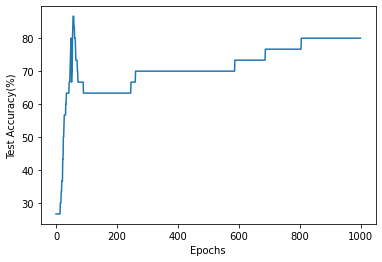

In [ ]:
plt.plot(range(0,epochs),test_list1)

plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")
plt.show

Confusion Matrix

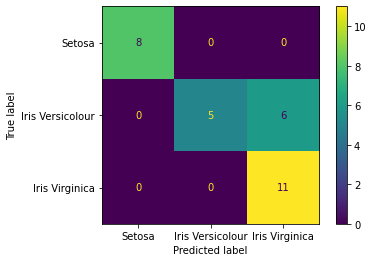

In [ ]:
pred = model(test_data)
pred = torch.argmax(pred,dim=1)
confusion_matrix = metrics.confusion_matrix(test_labels.numpy(),pred.numpy())
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels=["Setosa", "Iris Versicolour","Iris Virginica"])
cm_display.plot()
plt.show()

# Επαναλυψη εκπαίδευσης με συνάρτηση ενεργοποίησης Relu

Ορίζουμε το νευρωνικό δίκτυο με συνάρτηση Relu

In [ ]:
class NeuralNetwork2(nn.Module):
    def __init__(self):
        super(NeuralNetwork2, self).__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(4, 30),
            nn.ReLU(),
            nn.Linear(30,3),
        )

    def forward(self, x):
        logits = self.linear_stack(x)
        return logits

model2 = NeuralNetwork2()

Οι παράμετροι εκπαίδευσης του νέου δικτύου θα είναι ίδιες με αυτές του προηγούμενου δικτύου

In [ ]:
learning_rate = 0.01

# Initialize the loss function
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model2.parameters(), lr=learning_rate)

Εκπαίδευση δικτύου με συνάρτηση ενεργοποίησης Relu

In [ ]:
epochs = 1000
test_list2 = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_data,train_labels, model2, loss_fn, optimizer)
    acc,loss2 = test_loop(test_data_labels,train_data_labels, model2, loss_fn)
    test_list2.append(acc)
print("Done!")

Η έξοδος ροής περικόπηκε στις τελευταίες 5000 γραμμές.

Epoch 168
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.531857


Epoch 169
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.530713


Epoch 170
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.529579


Epoch 171
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.528453


Epoch 172
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.527335


Epoch 173
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.526225


Epoch 174
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.525123


Epoch 175
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.524028


Epoch 176
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.522942


Epoch 177
-------------------------------
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.521863


Epoc

Relu Test Accuracy

<function matplotlib.pyplot.show(*args, **kw)>

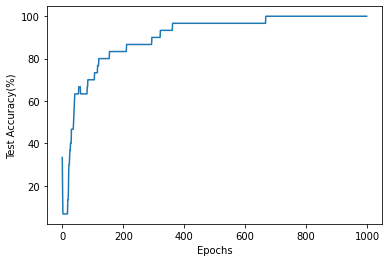

In [ ]:
plt.plot(range(0,epochs),test_list2)

plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")
plt.show

Relu Confusion Matrix

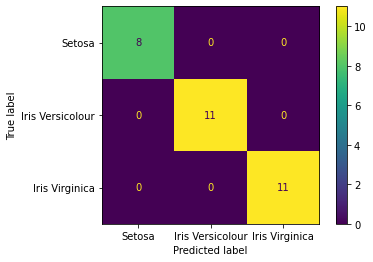

In [ ]:
pred = model2(test_data)
pred = torch.argmax(pred,dim=1)
confusion_matrix = metrics.confusion_matrix(test_labels.numpy(),pred.numpy())
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels=["Setosa", "Iris Versicolour","Iris Virginica"])
cm_display.plot()
plt.show()

Παρατηρούμε οτι το δίκτυο με την συνάρτηση ενεργοποίησης Relu παράγει καλύτερα αποτελέσματα αφού το δίκτυο χρειάζεται λιγότερες εποχές για να εκπαιδευτεί.

# Πειραματισμός με τις παραμέτρους σχεδίασης

**Δίκτυο 2 επιπέδων 35 νευρώνων με συνάρτηση ενεργοποίησης Relu και optimizer SGD momentum=0.8**

In [ ]:
class NeuralNetwork3(nn.Module):
    def __init__(self):
        super(NeuralNetwork3, self).__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(4, 35),
            nn.ReLU(),
            nn.Linear(35,3)
        )

    def forward(self, x):
        logits = self.linear_stack(x)
        return logits

model3 = NeuralNetwork3()

In [ ]:
learning_rate = 0.01

# Initialize the loss function
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model3.parameters(), lr=learning_rate,momentum=0.8)

In [ ]:
epochs = 1000
test_list3 = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_data,train_labels, model3, loss_fn, optimizer)
    acc,loss3 = test_loop(test_data_labels,train_data_labels, model3, loss_fn)
    test_list3.append(acc)
print("Done!")

Η έξοδος ροής περικόπηκε στις τελευταίες 5000 γραμμές.

Epoch 168
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.215689


Epoch 169
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.214762


Epoch 170
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.213845


Epoch 171
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.212936


Epoch 172
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.212037


Epoch 173
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.211145


Epoch 174
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.210263


Epoch 175
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.209389


Epoch 176
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.208524


Epoch 177
-------------------------------
Test Error: 
 Accuracy: 100.0%, Avg loss: 0.207

Test Accuracy Plot Comparison

<function matplotlib.pyplot.show(*args, **kw)>

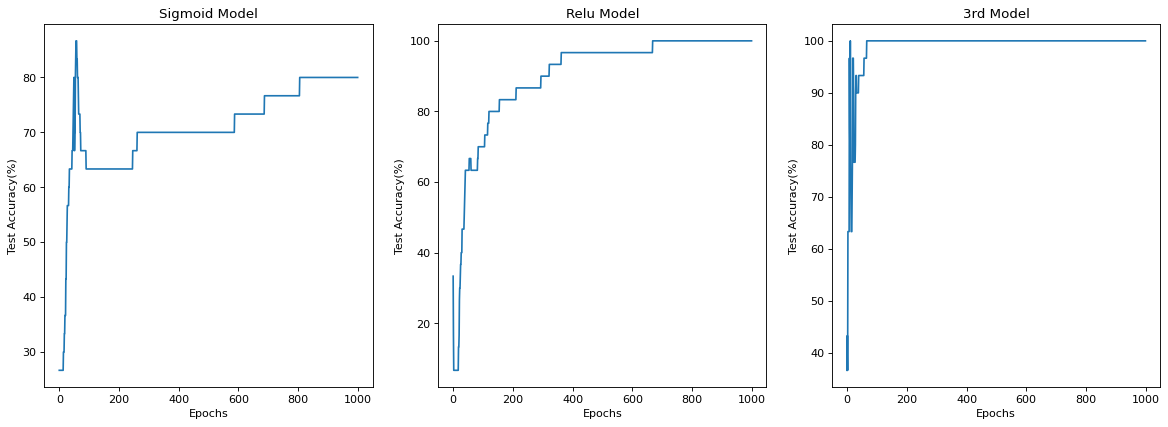

In [ ]:
plt.figure(figsize=(18, 6), dpi=80)

plt.subplot(1, 3, 1)
plt.plot(range(0,epochs),test_list1)
plt.title("Sigmoid Model")
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.subplot(1, 3, 2)
plt.plot(range(0,epochs),test_list2)
plt.title("Relu Model")
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.subplot(1, 3, 3)
plt.plot(range(0,epochs),test_list3)
plt.title("3rd Model")
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.show

Confusion Matrix Comparison

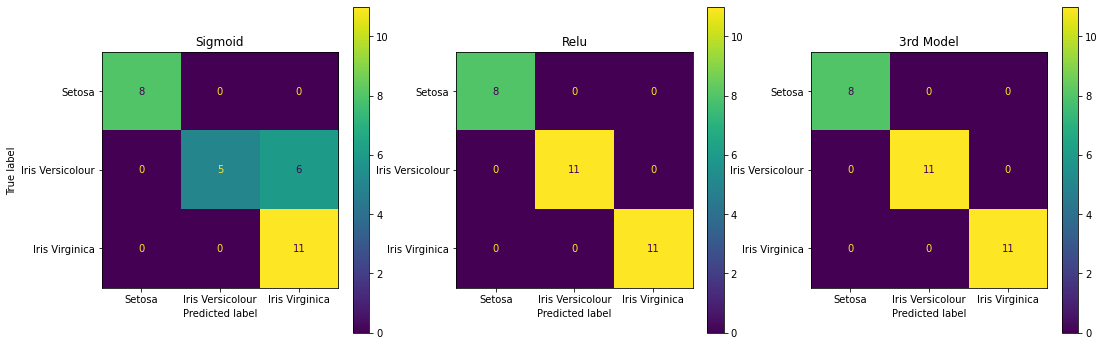

In [ ]:
pred = model(test_data)
pred = torch.argmax(pred,dim=1)
confusion_matrix1 = metrics.confusion_matrix(test_labels.numpy(),pred.numpy())

pred = model2(test_data)
pred = torch.argmax(pred,dim=1)
confusion_matrix2 = metrics.confusion_matrix(test_labels.numpy(),pred.numpy())

pred = model3(test_data)
pred = torch.argmax(pred,dim=1)
confusion_matrix3 = metrics.confusion_matrix(test_labels.numpy(),pred.numpy())


fig, ax = plt.subplots(1,3,figsize=(18, 6))

ax[0].set_title("Sigmoid")
ax[1].set_title("Relu")
ax[2].set_title("3rd Model")

metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix1, display_labels=["Setosa", "Iris Versicolour","Iris Virginica"]).plot(ax=ax[0])

metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix2, display_labels=["Setosa", "Iris Versicolour","Iris Virginica"]).plot(ax=ax[1]);

metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix3, display_labels=["Setosa", "Iris Versicolour","Iris Virginica"]).plot(ax=ax[2]);



In [ ]:
print(f" Model 1 ||Test Accuracy: {(test_list1[-1]):>0.1f}%   loss: {loss1:>8f}\n\n")
print(f" Model 2 ||Test Accuracy: {(test_list2[-1]):>0.1f}%   loss: {loss2:>8f}\n\n")
print(f" Model 3 ||Test Accuracy: {(test_list3[-1]):>0.1f}%   loss: {loss3:>8f}\n\n")

 Model 1 ||Test Accuracy: 80.0%   loss: 0.577033


 Model 2 ||Test Accuracy: 100.0%   loss: 0.201967


 Model 3 ||Test Accuracy: 100.0%   loss: 0.078765




Το τρίτο μοντέλο είναι πολύ καλύτερο από τα δύο προηγούμενα αφού έχει πολύ μικρότερο loss και χρεαιάζεται λιγότερες εποχές ωστε να σταθεροποιηθεί το test accuracy. Οι αλλαγές που έγιναν σε σχέση με το δευτερό μοντέλο είναι ο αριθμός των νευρώνων (35 αντί για 30) και ο optimizer (SGD με momentum=0.8 αντί για SGD). Ο λόγος που δεν μεταβλήθηκαν οι υπόλοιπες παράμετροι του δικτύου είναι επειδή το δευτερο μοντέλο είναι ήδη πολύ καλό.

Παρακάτω παρατίθονται μερικοί από τους πειραματισμούς που έγιναν

**Δίκτυο 3 επιπέδων 30 και 10 νευρώνων με συνάρτηση ενεργοποίησης Relu και optimizer SGD**

In [ ]:
class NeuralNetwork4(nn.Module):
    def __init__(self):
        super(NeuralNetwork4, self).__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(4, 30),
            nn.ReLU(),
            nn.Linear(30, 10),
            nn.ReLU(),
            nn.Linear(10,3)
        )

    def forward(self, x):
        logits = self.linear_stack(x)
        return logits

model4 = NeuralNetwork4()

In [ ]:
learning_rate = 0.01

# Initialize the loss function
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model4.parameters(), lr=learning_rate)

In [ ]:
epochs = 500
test_list4 = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_data,train_labels, model4, loss_fn, optimizer)
    acc,loss4 = test_loop(test_data_labels,train_data_labels, model4, loss_fn)
    test_list4.append(acc)
print("Done!")

Epoch 1
-------------------------------
Test Error: 
 Accuracy: 0.0%, Avg loss: 1.203722


Epoch 2
-------------------------------
Test Error: 
 Accuracy: 0.0%, Avg loss: 1.193349


Epoch 3
-------------------------------
Test Error: 
 Accuracy: 3.3%, Avg loss: 1.183771


Epoch 4
-------------------------------
Test Error: 
 Accuracy: 26.7%, Avg loss: 1.174909


Epoch 5
-------------------------------
Test Error: 
 Accuracy: 33.3%, Avg loss: 1.166660


Epoch 6
-------------------------------
Test Error: 
 Accuracy: 33.3%, Avg loss: 1.158943


Epoch 7
-------------------------------
Test Error: 
 Accuracy: 33.3%, Avg loss: 1.151695


Epoch 8
-------------------------------
Test Error: 
 Accuracy: 36.7%, Avg loss: 1.144857


Epoch 9
-------------------------------
Test Error: 
 Accuracy: 36.7%, Avg loss: 1.138381


Epoch 10
-------------------------------
Test Error: 
 Accuracy: 36.7%, Avg loss: 1.132225


Epoch 11
-------------------------------
Test Error: 
 Accuracy: 36.7%, Avg loss: 

**Δίκτυο 3 επιπέδων 30 και 10 νευρώνων με συνάρτηση ενεργοποίησης Tanh και optimizer SGD (momentum=0,8)**


In [ ]:
class NeuralNetwork5(nn.Module):
    def __init__(self):
        super(NeuralNetwork5, self).__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(4, 30),
            nn.Tanh(),
            nn.Linear(30, 10),
            nn.Tanh(),
            nn.Linear(10,3)
        )

    def forward(self, x):
        logits = self.linear_stack(x)
        return logits

model5 = NeuralNetwork5()

In [ ]:
learning_rate = 0.01

# Initialize the loss function
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model5.parameters(), lr=learning_rate,momentum=0.8)

In [ ]:
epochs = 500
test_list5 = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_data,train_labels, model5, loss_fn, optimizer)
    acc,loss5 = test_loop(test_data_labels,train_data_labels, model5, loss_fn)
    test_list5.append(acc)
print("Done!")

Epoch 1
-------------------------------
Test Error: 
 Accuracy: 26.7%, Avg loss: 1.085151


Epoch 2
-------------------------------
Test Error: 
 Accuracy: 26.7%, Avg loss: 1.082503


Epoch 3
-------------------------------
Test Error: 
 Accuracy: 33.3%, Avg loss: 1.078935


Epoch 4
-------------------------------
Test Error: 
 Accuracy: 53.3%, Avg loss: 1.074648


Epoch 5
-------------------------------
Test Error: 
 Accuracy: 53.3%, Avg loss: 1.069801


Epoch 6
-------------------------------
Test Error: 
 Accuracy: 50.0%, Avg loss: 1.064516


Epoch 7
-------------------------------
Test Error: 
 Accuracy: 53.3%, Avg loss: 1.058883


Epoch 8
-------------------------------
Test Error: 
 Accuracy: 53.3%, Avg loss: 1.052969


Epoch 9
-------------------------------
Test Error: 
 Accuracy: 53.3%, Avg loss: 1.046818


Epoch 10
-------------------------------
Test Error: 
 Accuracy: 46.7%, Avg loss: 1.040460


Epoch 11
-------------------------------
Test Error: 
 Accuracy: 50.0%, Avg los

**Δίκτυο 2 επιπέδων 35 νευρώνων με συνάρτηση ενεργοποίησης Relu και opptimizer SGD με momentum=0.8**

In [ ]:
class NeuralNetwork6(nn.Module):
    def __init__(self):
        super(NeuralNetwork6, self).__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(4, 35),
            nn.ReLU(),
            nn.Linear(35,3),
        )

    def forward(self, x):
        logits = self.linear_stack(x)
        return logits

model6 = NeuralNetwork6()

In [ ]:
learning_rate = 0.01

# Initialize the loss function
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model6.parameters(), lr=learning_rate)

In [ ]:
epochs = 500
test_list6 = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_data,train_labels, model6, loss_fn, optimizer)
    acc,loss6 = test_loop(test_data_labels,train_data_labels, model6, loss_fn)
    test_list6.append(acc)
print("Done!")

Epoch 1
-------------------------------
Test Error: 
 Accuracy: 36.7%, Avg loss: 1.340635


Epoch 2
-------------------------------
Test Error: 
 Accuracy: 36.7%, Avg loss: 1.077401


Epoch 3
-------------------------------
Test Error: 
 Accuracy: 76.7%, Avg loss: 0.974072


Epoch 4
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.979634


Epoch 5
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 1.013212


Epoch 6
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 1.029095


Epoch 7
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 1.014654


Epoch 8
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.973533


Epoch 9
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.916216


Epoch 10
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg loss: 0.852817


Epoch 11
-------------------------------
Test Error: 
 Accuracy: 63.3%, Avg los

<function matplotlib.pyplot.show(*args, **kw)>

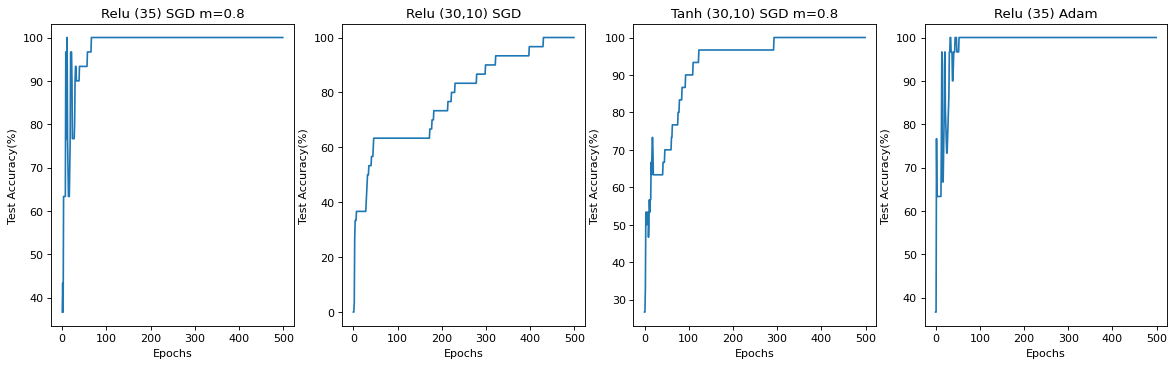

In [ ]:
plt.figure(figsize=(18, 5), dpi=80)

plt.subplot(1, 4, 1)
plt.plot(range(0,epochs),test_list3[0:500])
plt.title("Relu (35) SGD m=0.8")
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.subplot(1, 4, 2)
plt.plot(range(0,epochs),test_list4)
plt.title("Relu (30,10) SGD")
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.subplot(1, 4, 3)
plt.plot(range(0,epochs),test_list5)
plt.title("Tanh (30,10) SGD m=0.8")
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.subplot(1, 4, 4)
plt.plot(range(0,epochs),test_list6)
plt.title("Relu (35) Adam")
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.show

In [ ]:
print(f" Model   |Act. Fun | Neurons | Optimizer  | Test Accuracy   loss\n\n")
print(f" Model 1  Sigmoid   (30)       SGD        | {(test_list1[-1]):>0.1f}%       {loss1:>8f}\n\n")
print(f" Model 2  Relu      (30)       SGD        | {(test_list2[-1]):>0.1f}%       {loss2:>8f}\n\n")
print(f" Model 3  Relu      (35)       SGD m=0.8  | {(test_list3[-1]):>0.1f}%       {loss3:>8f}\n\n")
print(f" Model 4  Relu      (30,10)    SGD        | {(test_list4[-1]):>0.1f}%       {loss4:>8f}\n\n")
print(f" Model 5  Tanh      (30,10)    SGD m=0.8  | {(test_list5[-1]):>0.1f}%       {loss5:>8f}\n\n")
print(f" Model 6  Relu      (35)       Adam       | {(test_list6[-1]):>0.1f}%       {loss6:>8f}\n\n")

 Model   |Act. Fun | Neurons | Optimizer  | Test Accuracy   loss


 Model 1  Sigmoid   (30)       SGD        | 80.0%       0.577033


 Model 2  Relu      (30)       SGD        | 100.0%       0.201967


 Model 3  Relu      (35)       SGD m=0.8  | 100.0%       0.078765


 Model 4  Relu      (30,10)    SGD        | 100.0%       0.309311


 Model 5  Tanh      (30,10)    SGD m=0.8  | 100.0%       0.085877


 Model 6  Relu      (35)       Adam       | 100.0%       0.037413




Το δίκτυο 3 επίπεδων (30,10) και optimizer SGD συγκλίνει πιο αργά από τα υπόλοιπα. Παρατηρείται όμως ότι με  Adam optimizer ή με SGD optimizer με momentum=0.8 τα δίκτυα έχουν πολύ καλή απόδοση. Επειδή το test accuracy και το test loss των δικτύων 3,5 και 6 είναι πολύ κοντα αλλά μεταβάλονται σε κάθε εκτέλεση λόγω της τυχαιότητας που υαρχει στην εκπαίδευση (διαμοιρασμός δεδομένων και αρχικοποίηση βαρών) δεν μπορούμε να δηλώσουμε με σιγουριά ποιο είναι το καλύτερο δίκτυο.

Συνολικά τα δίκτυα 3,5 και 6 έχουν όλα καλύτερη απόδοση από τα δύο αρχικά.